# E15 — 일반 replay · seed 42
E10 유지: DDQN / 84×84 / stack 4 / skip 4 / 300,000 원본 프레임. T4 GPU 선택 후 순서대로 실행.
검증 500–504로 best 선택, 공개 비교 1000–1009. 학습 seed는 초기화·탐색·학습 트랙을 함께 변경합니다. E14는 CPU였으므로 GPU 차이도 기록합니다.

## 1. Drive와 코드 준비
최초 실행만 GitHub에서 복사. 기존 Drive 코드와 결과는 자동 갱신하지 않습니다.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
import os, sys, subprocess, json, shutil, tempfile
ROOT=Path('/content/drive/MyDrive/261103')
RESULTS=ROOT/'261103_results'
if not (ROOT/'train.py').exists():
    with tempfile.TemporaryDirectory() as tmp:
        subprocess.run(['git','clone','--depth','1','--branch','261103','https://github.com/MilkySon/RL_carracing_competition.git',tmp+'/repo'],check=True)
        shutil.copytree(Path(tmp)/'repo'/'261103',ROOT,dirs_exist_ok=True)
RESULTS.mkdir(parents=True,exist_ok=True)
os.chdir(ROOT)
os.environ['SDL_VIDEODRIVER']='dummy'
os.environ['SDL_AUDIODRIVER']='dummy'
print(ROOT,RESULTS)


Mounted at /content/drive
/content/drive/MyDrive/261103 /content/drive/MyDrive/261103/261103_results


## 2. 설치

In [2]:
subprocess.run([sys.executable,'-m','pip','install','-q','swig'],check=True)
subprocess.run([sys.executable,'-m','pip','install','-q','-r','requirements.txt'],check=True)
import torch
print('GPU:',torch.cuda.is_available())
def run(args,log):
    log=Path(log);log.parent.mkdir(parents=True,exist_ok=True)
    with log.open('a') as f:
        p=subprocess.Popen(list(map(str,args)),stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True,bufsize=1)
        for line in p.stdout: print(line,end='');f.write(line);f.flush()
        rc=p.wait()
    if rc:raise RuntimeError(f'Failed ({rc}): {log}')


GPU: True


## 3. 독립 학습
중단된 기록은 새 RUN_NAME으로 처음부터 실행. 원본 resume은 replay/RNG 미복원이므로 자동 사용하지 않습니다. replay는 GPU와 별개로 호스트 RAM을 많이 사용할 수 있습니다.

In [3]:
RUN_NAME='E15'
RUN_DIR=RESULTS/RUN_NAME
ALLOW_CPU=False
if not torch.cuda.is_available() and not ALLOW_CPU:raise RuntimeError('GPU를 선택하거나 ALLOW_CPU=True로 설정하세요.')
RUN_DIR.mkdir(parents=True,exist_ok=True)
if (RUN_DIR/'final.pt').exists():print('완료된 학습 사용:',RUN_DIR)
elif any((RUN_DIR/n).exists() for n in ['train.csv','eval.csv','latest.pt','best.pt']):
    raise RuntimeError('중단된 결과가 있습니다. 새 RUN_NAME을 사용하세요.')
else:
    import hashlib,platform
    manifest={'agent':'ddqn_e10','seed':42,'budget':300000,'python':platform.python_version(),
        'torch':torch.__version__,'device':torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu',
        'source_sha256':{str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in ROOT.rglob('*.py') if '261103_results' not in p.parts}}
    (RUN_DIR/'manifest.json').write_text(json.dumps(manifest,indent=2))
    run([sys.executable,'train.py','--agent','ddqn_e10','--seed',42,'--budget',300000,'--eval-every',50000,'--run-dir',RUN_DIR],RUN_DIR/'training_console.log')
assert (RUN_DIR/'best.pt').exists()


/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists
agent=ddqn_e10 action=discrete device=cuda budget=300,000 frames
[    1,000] ep    1 return   -63.6 (80 fps) 
[    2,000] ep    2 return   -58.5 (79 fps) 
[    3,000] ep    3 return   -43.8 (87 fps) 
[    4,000] ep    4 return   -40.8 (88 fps) 
[    5,000] ep    5 return   -58.6 (90 fps) 
[    6,000] ep    6 return   -21.0 (94 fps) 
[    7,000] ep    7 return    -2.3 (94 fps) 
[    8,000] ep    8 return   -60.7 (94 fps) 
[    9,000] ep    9 return   -43.0 (96 fps) 
[   10,000] ep   10 return   -18.9 (96 fps) 
[   11,000] ep   11 return   -18.7 (96 fps) 
[   12,000] ep   12 return   -32.4 (97 fps) 
[   13,000] ep   13 return   -

## 4. 학습 곡선

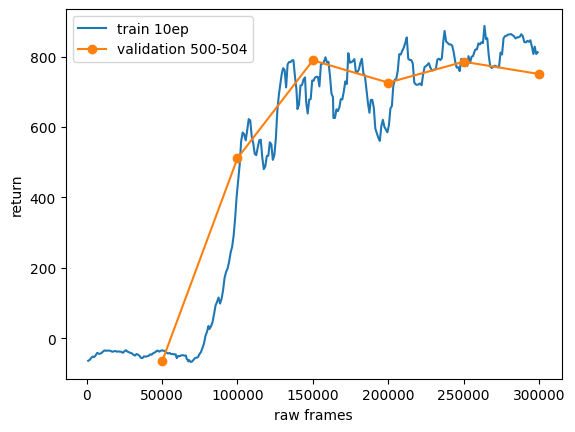

,frames,score,std
0,50000,-65.620165,37.278082
1,100002,511.502978,225.521906
2,150000,789.090468,204.623166
3,200001,725.800410,158.686808
4,250003,785.136732,154.477599
5,300000,750.293711,40.504424


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
tr=pd.read_csv(RUN_DIR/'train.csv');ev=pd.read_csv(RUN_DIR/'eval.csv')
plt.plot(tr.frames,tr['return'].rolling(10,min_periods=1).mean(),label='train 10ep')
plt.plot(ev.frames,ev.score,'o-',label='validation 500-504')
plt.xlabel('raw frames');plt.ylabel('return');plt.legend();plt.show()
display(ev)


## 5. 평가·영상
best/final을 비교해 후반 성능 하락을 진단합니다. 2000–2029는 추가 개발 평가이며 최종 시험과 분리하세요.

In [5]:
for d in ['reports','videos','onnx']:(RUN_DIR/d).mkdir(exist_ok=True)
for ckpt in ['best','final']:
    for seeds in ['1000-1009','2000-2029']:
        run([sys.executable,'evaluate.py','--ckpt',RUN_DIR/f'{ckpt}.pt','--seeds',seeds,'--out',RUN_DIR/'reports'/f'{ckpt}_{seeds}.json'],RUN_DIR/'evaluation_console.log')
run([sys.executable,'evaluate.py','--ckpt',RUN_DIR/'best.pt','--seeds','1000-1002','--video',RUN_DIR/'videos'],RUN_DIR/'video_console.log')
from IPython.display import Video,display
videos=sorted((RUN_DIR/'videos').glob('*.mp4'))
if videos:display(Video(str(videos[0]),embed=True,width=400))
rows=[]
for p in sorted((RUN_DIR/'reports').glob('best_*.json')):
    obj=json.loads(p.read_text());v=sorted(obj['returns']);k=max(1,len(v)//5)
    rows.append(dict(report=p.stem,mean=obj['mean'],std=obj['std'],below700=sum(x<700 for x in v),bottom20_mean=sum(v[:k])/k))
summary=pd.DataFrame(rows);display(summary);summary.to_csv(RUN_DIR/'reports'/'summary.csv',index=False)


/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists
seed 1000:    572.4
seed 1001:    598.7
seed 1002:    863.6
seed 1003:    783.3
seed 1004:    886.6
seed 1005:     34.8
seed 1006:    915.7
seed 1007:    272.2
seed 1008:    688.0
seed 1009:    918.6
SCORE (mean over 10 tracks): 653.4 ± 281.7
/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists
seed 2000:    610.4
seed 20

,report,mean,std,below700,bottom20_mean
0,best_1000-1009,653.390692,281.653812,5,153.506228
1,best_2000-2029,765.136984,189.053315,8,455.243575


## 6. ONNX 제출기 검증

In [6]:
TEAM_NAME='MyTeam'
model=RUN_DIR/'onnx'/f'{TEAM_NAME}_E15.onnx'
run([sys.executable,'export.py','--ckpt',RUN_DIR/'best.pt','--out',model],RUN_DIR/'export_console.log')
run([sys.executable,'check_submission.py','--onnx',model,'--seeds','1000-1009','--json',RUN_DIR/'reports'/'onnx_1000-1009.json'],RUN_DIR/'submission_console.log')
print('다음: E16_colab_quickstart.ipynb')


/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists
saved /content/drive/MyDrive/261103/261103_results/E15/onnx/MyTeam_E15.onnx  (continuous=False, frame_skip=4, n_stack=4)
행동 일치율: 100.0% (250 steps)
제출 전 확인: python check_submission.py --onnx /content/drive/MyDrive/261103/261103_results/E15/onnx/MyTeam_E15.onnx
/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists
설정: {'con